# chip_08_tl_hsq_testpads — 45 HSQ trilayer junction test pads, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_08_TL_HSQ_testpads.py` (`create_test_chip()`, writes `chip_08_TL_HSQ_testJJ_1.0.gds`,
May 2024), Quantcore internal. Spec: `docs/designs/legacy/chip_08_tl_hsq_testpads.md`.

A 7.5 × 7.5 mm junction-size calibration die for the HSQ-spacer trilayer process: a 9 × 5 array of
`testPad_Nb_TL_HSQ` probe structures (two 500 × 400 µm pads across a 300 µm gap, an HSQ-spacer trilayer junction
between the tips) on chip_04's grid; the straight (bottom) finger is swept 0.3 … 1.0 µm along the columns, the bent
(top) finger is 0.6 µm in every row. Column labels give the straight finger in nm; HSQ corner markers on the HSQ
layer. The legacy imports of `junction_creator_HSQ` and `testPad` are unused; the header comment ("50 junctions",
11 × 5 fingers) is stale — the code draws 9 × 5 = 45 pads, and this notebook follows the code.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| test pads, labels, markers | the 45 `testPad_Nb_TL_HSQ` structures (`JunctionTestPads`), the nine column labels (`TextLabel`, inverted, mag 100) and the HSQ corner markers (`CornerMarker`, `hsq=True`) at the legacy positions | the fingers valued on the PDK process, never resized |
| bond pads | — (probe pads belong to the test structures; no bond pads or launchers) | the pad rule (`frame.pad_edge`, 100 µm) has nothing to move (step 4) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | the legacy grid | centred in the die where > 50 µm off (labels left out of the measure): already centred (step 7) |
| frame | — | the PDK die frame and device ID `CHIP08 TL HSQ` (bottom edge centre, free) instead of the base-metal corner `Marker`s and the layer-10 outline |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the 45 test pads and the column labels at the legacy positions, XOR-identical to the legacy output.

### Changes after design review (2026-11-03)

- **#1 junction values — PDK trilayer rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ for the
  qubits): the drawn legacy test-pad fingers are kept (the sweep is the point of a test chip) and valued on the PDK
  process (R_n·A 13.5 kΩ·µm², C_J 50 fF/µm², both assumed by the PDK; 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH; R_n ∝
  1/area). The earlier assumed J_c = 1 µA/µm² is gone. Values in step 10.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** none. The probe pads belong to the test structures and are not bond pads or launchers, so the pad rule
  (`frame.pad_edge`, 100 µm) has nothing to move; `C.pads_md(d)` confirms it (step 7).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, 0): the legacy grid is already centred (labels left out of the measure).
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks (`_legacy_b`, `LB`, adds the legacy cells of the later chips). `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # Connector Pad 2, holes, labels, xjc scripts, junction XOR
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_08_tl_hsq_testpads", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

`chip_08_TL_HSQ_testpads.py`'s numbers in its own (0, 0)-centred frame (µm): the finger sweep (bent finger 0.6 µm
throughout) and chip_04's `np.arange` grids; the column labels at (x − 190, 3350).

In [4]:
# chip_08_TL_HSQ_testpads.py, legacy frame (µm)
BOTTOM_FINGER = [0.3, 0.4, 0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 1.0]   # per column: create_testPad(bf / 0.2, tf)
TOP_FINGER = [0.6, 0.6, 0.6, 0.6, 0.6]                           # per row
X = [-7500 / 2 + 650 + 300 + 700 * i for i in range(9)]          # np.arange(-box/2 + 950, box/2 - 800, 700)
Y = [7500 / 2 - 1350 - 1200 * j for j in range(5)]               # np.arange(box/2 - 1350, -box/2 + 1000, -1200)
LABEL_Y = 3350                                                   # column labels at (x - 190, 3350), mag 100, inv
SCRIPT = "testPad_Nb_TL_HSQ"
params = [legacy_test_pad_params(SCRIPT, bf / 0.2, tf) for bf in BOTTOM_FINGER for tf in TOP_FINGER]
shared = {k: v for k, v in params[0].items() if k not in ("finger_width", "second_finger_width")}

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP08 TL HSQ` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


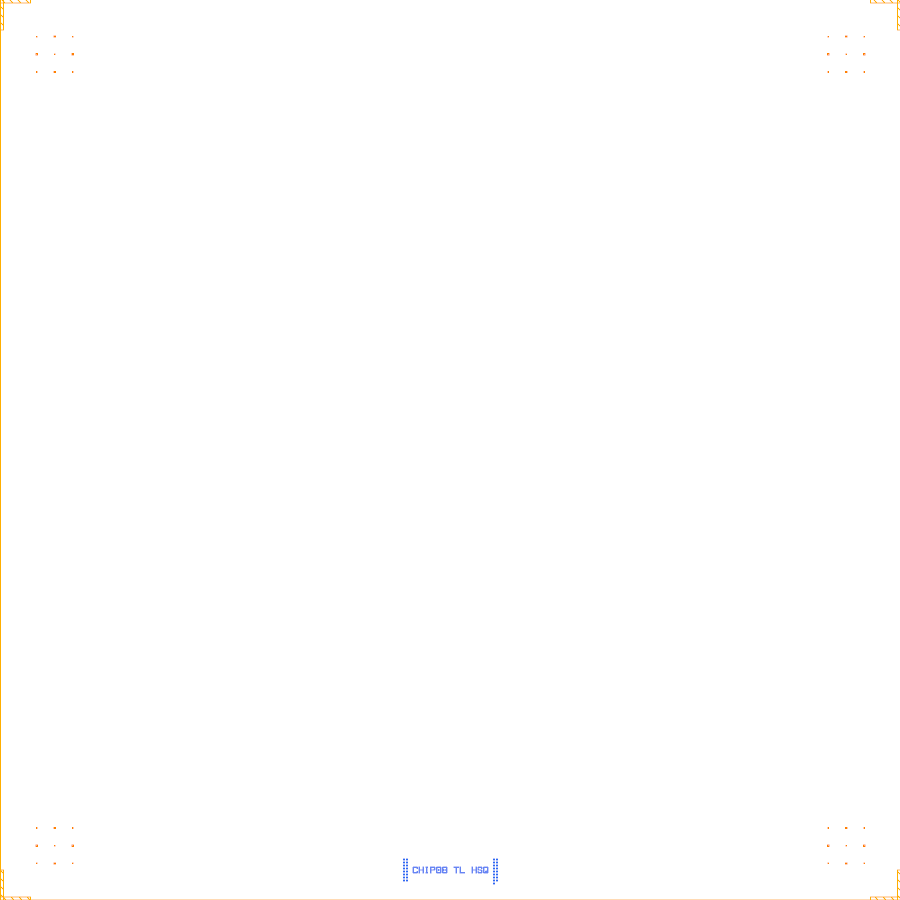

WindowsPath('build/legacy_steps/chip_08_tl_hsq_testpads_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP08 TL HSQ"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): does not apply

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). This chip has none: its probe pads are part of the test structures (placed in step 5, at the
source's positions, all well inside the design area). Step 7 lists the chip's bond pads with `C.pads_md(d)`: none.

## 5 · Components: the test structures

One `d.array` of `JunctionTestPads` (9 × 5, pitch 700 × −1200 µm, `vary` sets the finger widths), the nine column
labels and the four HSQ corner markers. Nothing has a port.

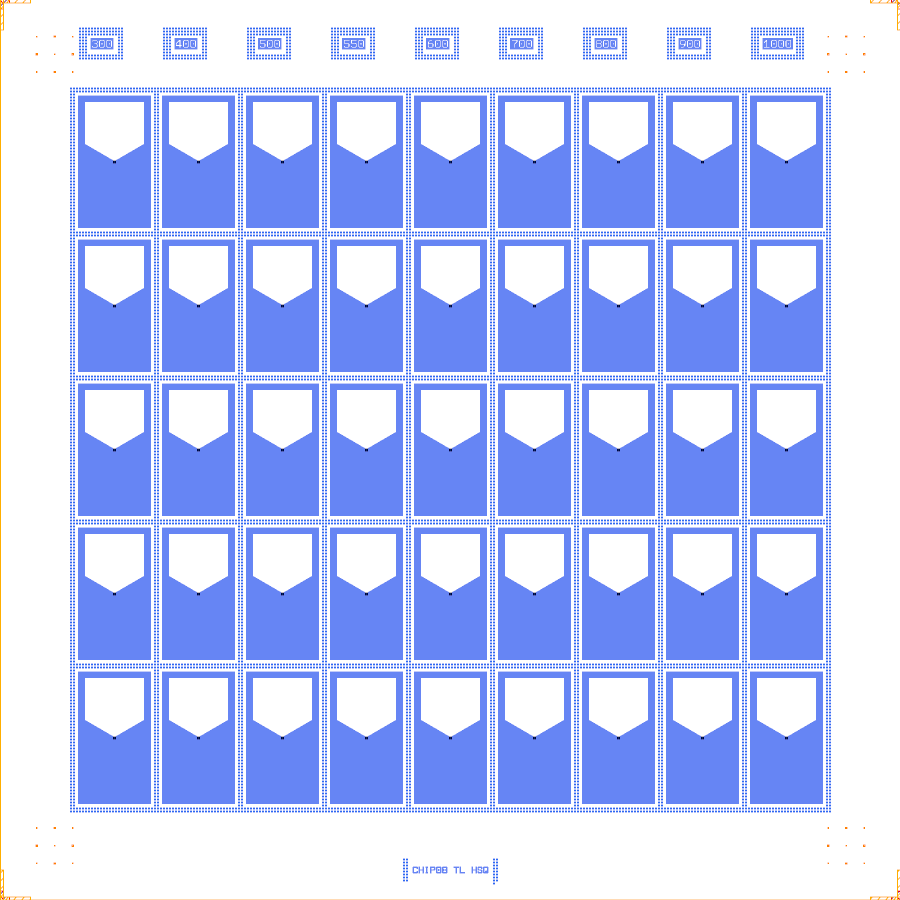

WindowsPath('build/legacy_steps/chip_08_tl_hsq_testpads_2_testpads.png')

In [6]:
with d.batch():
    pads = d.array("TP", "JunctionTestPads", origin=L.at(X[0], Y[0]), pitch=(700, -1200), shape=(9, 5),
                   vary={"finger_width": [p["finger_width"] for p in params],
                         "second_finger_width": [p["second_finger_width"] for p in params]}, **shared)
    for i, (x, bf) in enumerate(zip(X, BOTTOM_FINGER)):
        d.add(f"LBL_{i}", "TextLabel", **L.place(x - 190, LABEL_Y), text=str(int(bf * 1000)), mag=100, inverted=True)
    for k, (x, y, rot) in enumerate([(-3750, -3750, 1), (3750, -3750, 2), (3750, 3750, 3), (-3750, 3750, 0)]):
        d.add(f"HSQ{k}", "CornerMarker", **L.place(x, y, rot), hsq=True, thickness=50, width=150)
L.step_snapshot(d, "2_testpads")

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved, and `C.pads_md(d)` checks the pad rule (no bond pads).

centring shift (µm): (0.0, 0.0) | <Designer chip_08_tl_hsq_testpads: 58 instances, 0 routes, live=False> → examples\designs\legacy\chip_08_tl_hsq_testpads.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

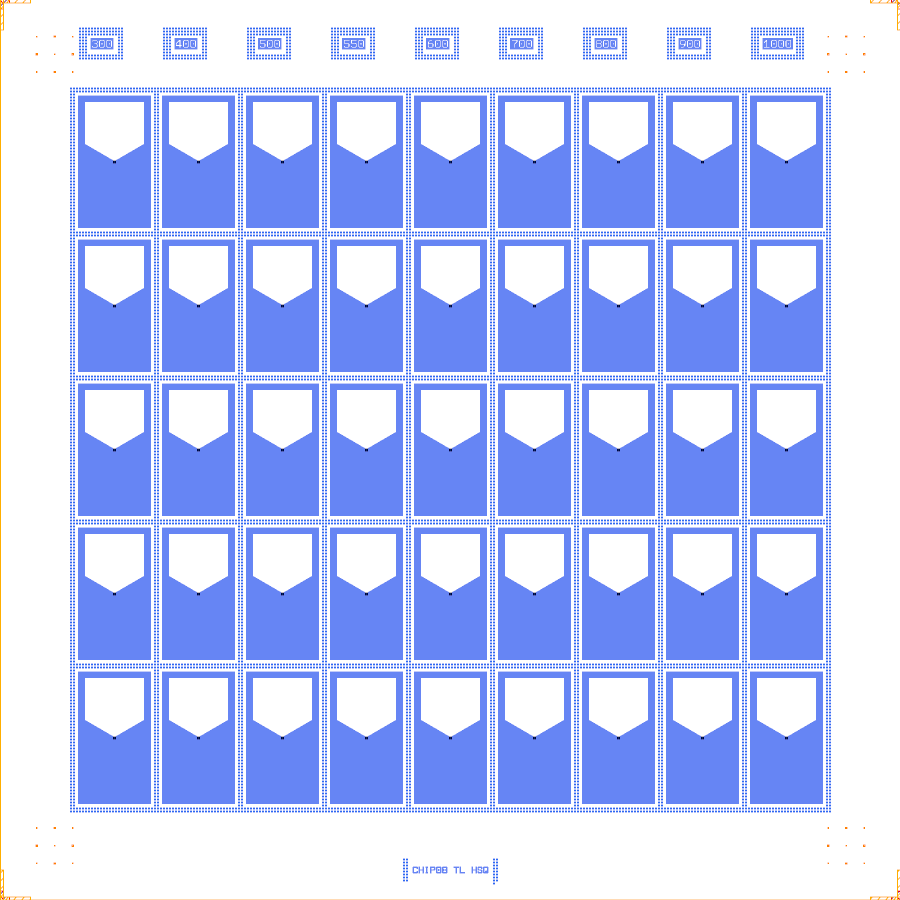

WindowsPath('build/legacy_steps/chip_08_tl_hsq_testpads_3_centred.png')

In [7]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors. Warnings, all from legacy positions kept as drawn: `frame_margin` / `frame_keepout`
HSQ0–HSQ3 (8: the HSQ markers sit at the die corners, in the dicing margin and the dicing-marker areas; HSQ layer,
not the base metal; as on chip_05 and chip_06). The pads (outermost windows at |x| ≤ 3100, |y| ≤ 2950 legacy) and
the labels stay inside the design area; the device ID `CHIP08 TL HSQ` has the bottom edge centre to itself,
(3400, 100)–(4100, 400) µm. `pdk_report`: cheese "PDK band", content centre (+0, +0) µm, junction types "—" (no
lumped junction values on the pads), 0 PDK design warnings.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning frame_margin  HSQ0 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ0 overlaps the dicing_markers_sw
warning frame_margin  HSQ1 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ1 overlaps the dicing_markers_se
warning frame_margin  HSQ2 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ2 overlaps the dicing_markers_ne
warning frame_margin  HSQ3 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ3 overlaps the dicing_markers_nw


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The test pads, labels and HSQ markers are port-less probe structures without a LOM model, so the netlist is empty (only ground, no branches, nothing unconnected): there is no circuit.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 10 · LOM simulation: does not apply — the junction table instead

A test-structure chip has no qubit or resonator to simulate; the junction values follow from the drawn finger
widths: area = straight × bent finger (bf × 0.6 µm²), R_n = (R_n·A) / area, L_J from Ambegaokar–Baratoff
(`circuit.bridges`), on the PDK junction rule.

In [10]:
display(Markdown(L.junction_grid(BOTTOM_FINGER, sorted(set(TOP_FINGER)),
                                 lambda bf, tf: (legacy_test_pad_params(SCRIPT, bf / 0.2, tf)["finger_width"], tf))))

L_J (nH) / R_n (kΩ) per test pad, drawn fingers on the PDK process. PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Area = straight × bent finger.

| top finger (µm) \ bottom finger (µm) | 0.3 | 0.4 | 0.5 | 0.55 | 0.6 | 0.7 | 0.8 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|---|---|
| 0.6 | 11.22 / 75.0 | 8.42 / 56.2 | 6.73 / 45.0 | 6.12 / 40.9 | 5.61 / 37.5 | 4.81 / 32.1 | 4.21 / 28.1 | 3.74 / 25.0 | 3.37 / 22.5 |

**Reading the numbers** (this run): with the 0.6 µm bent finger the straight-finger sweep 0.3 … 1.0 µm gives R_n 75.0,
56.2, 45.0, 40.9, 37.5, 32.1, 28.1, 25.0 and 22.5 kΩ: the 0.5 µm (45 kΩ, the PDK nominal) and 0.55 µm (40.9 kΩ)
columns lie in the 40–50 kΩ window.

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [11]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

A copy gives the first pad (`TP_0_0`, 0.3 × 0.6 µm: 75 kΩ) a 0.5 µm straight finger, the PDK nominal junction (45
kΩ), rebuilds it and checks it. The copy is not saved; the chip keeps the legacy sweep (its column 3 already has
the nominal size).

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
p = dict(d2.data["instances"]["TP_0_0"]["params"])
d2["TP_0_0"].set(finger_width=0.5)
display(Markdown(L.junction_table([("TP_0_0 as drawn", p["finger_width"], p["second_finger_width"], 1),
                                   ("TP_0_0, straight finger 0.5 µm", 0.5, p["second_finger_width"], 1)])))
print("copy rebuilt:", d2.drc().ok, "(no DRC errors)")

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| TP_0_0 as drawn | 0.3 × 0.6 | 1 | 0.1800 | 75.00 | 29.3 | 11.224 | 9.00 |
| TP_0_0, straight finger 0.5 µm | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |

copy rebuilt: True (no DRC errors)


**Result** (this run): `TP_0_0` with a 0.5 µm straight finger: R_n 75.0 → 45.0 kΩ (L_J 11.22 → 6.73 nH); the copy
rebuilds without DRC errors.

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_08_tl_hsq_testpads.json                    # layout → build/chip_08_tl_hsq_testpads.oas
qcc mask  examples/designs/legacy/chip_08_tl_hsq_testpads.json          # fab mask with the PDK rules
```

In [14]:
display(Markdown(L.fab_md(d)))

examples\designs\legacy\_legacy.py:747: FabLayersDropped: export_fab(chip_08_tl_hsq_testpads): PDK quantcore_nb_sapphire_v1 has no fab layer for qcc hsq_boundary (150/0): 8 shape(s); not written
  path = export_fab(d.result, path or Path("build") / f"{d.design.name}_fab.oas", report=rep, cheese=cheese)


Fab mask: `build/chip_08_tl_hsq_testpads_fab.oas` · cheese source **build** (8647 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 8736 |
| 2/0 | JJ_STRAIGHT | 45 |
| 3/0 | M3 | 8706 |
| 4/0 | JJ_BENT | 45 |
| 50/0 | HSQ | 94 |
| 51/0 | SPACER_1 | 90 |
| 52/0 | SPACER_2 | 90 |
| 53/0 | SPACER_3 | 90 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Not in the mask (no PDK fab layer):** qcc hsq_boundary (150/0) (8)

## 15 · Snapshots and comparison with the legacy geometry

Full chip; the first test pad (bf 0.3 µm) with its column label; its junction with the HSQ spacer boxes; the lower-left corner (400 µm) with the frame's dicing marker, the HSQ marker and the PDK band.

Then the same chip drawn by the author's legacy scripts (run read-only through `tests/legacy_ref`: one
`testPad_Nb_TL_HSQ.create_testPad(bf / 0.2, tf)` per pad and the `TextGenerator` column labels), moved by the
centring shift, and the etch XOR per legacy instance (PDK M1; slivers ≤ 2 nm ignored). The legacy corner `Marker`s
are replaced by the frame and not compared.

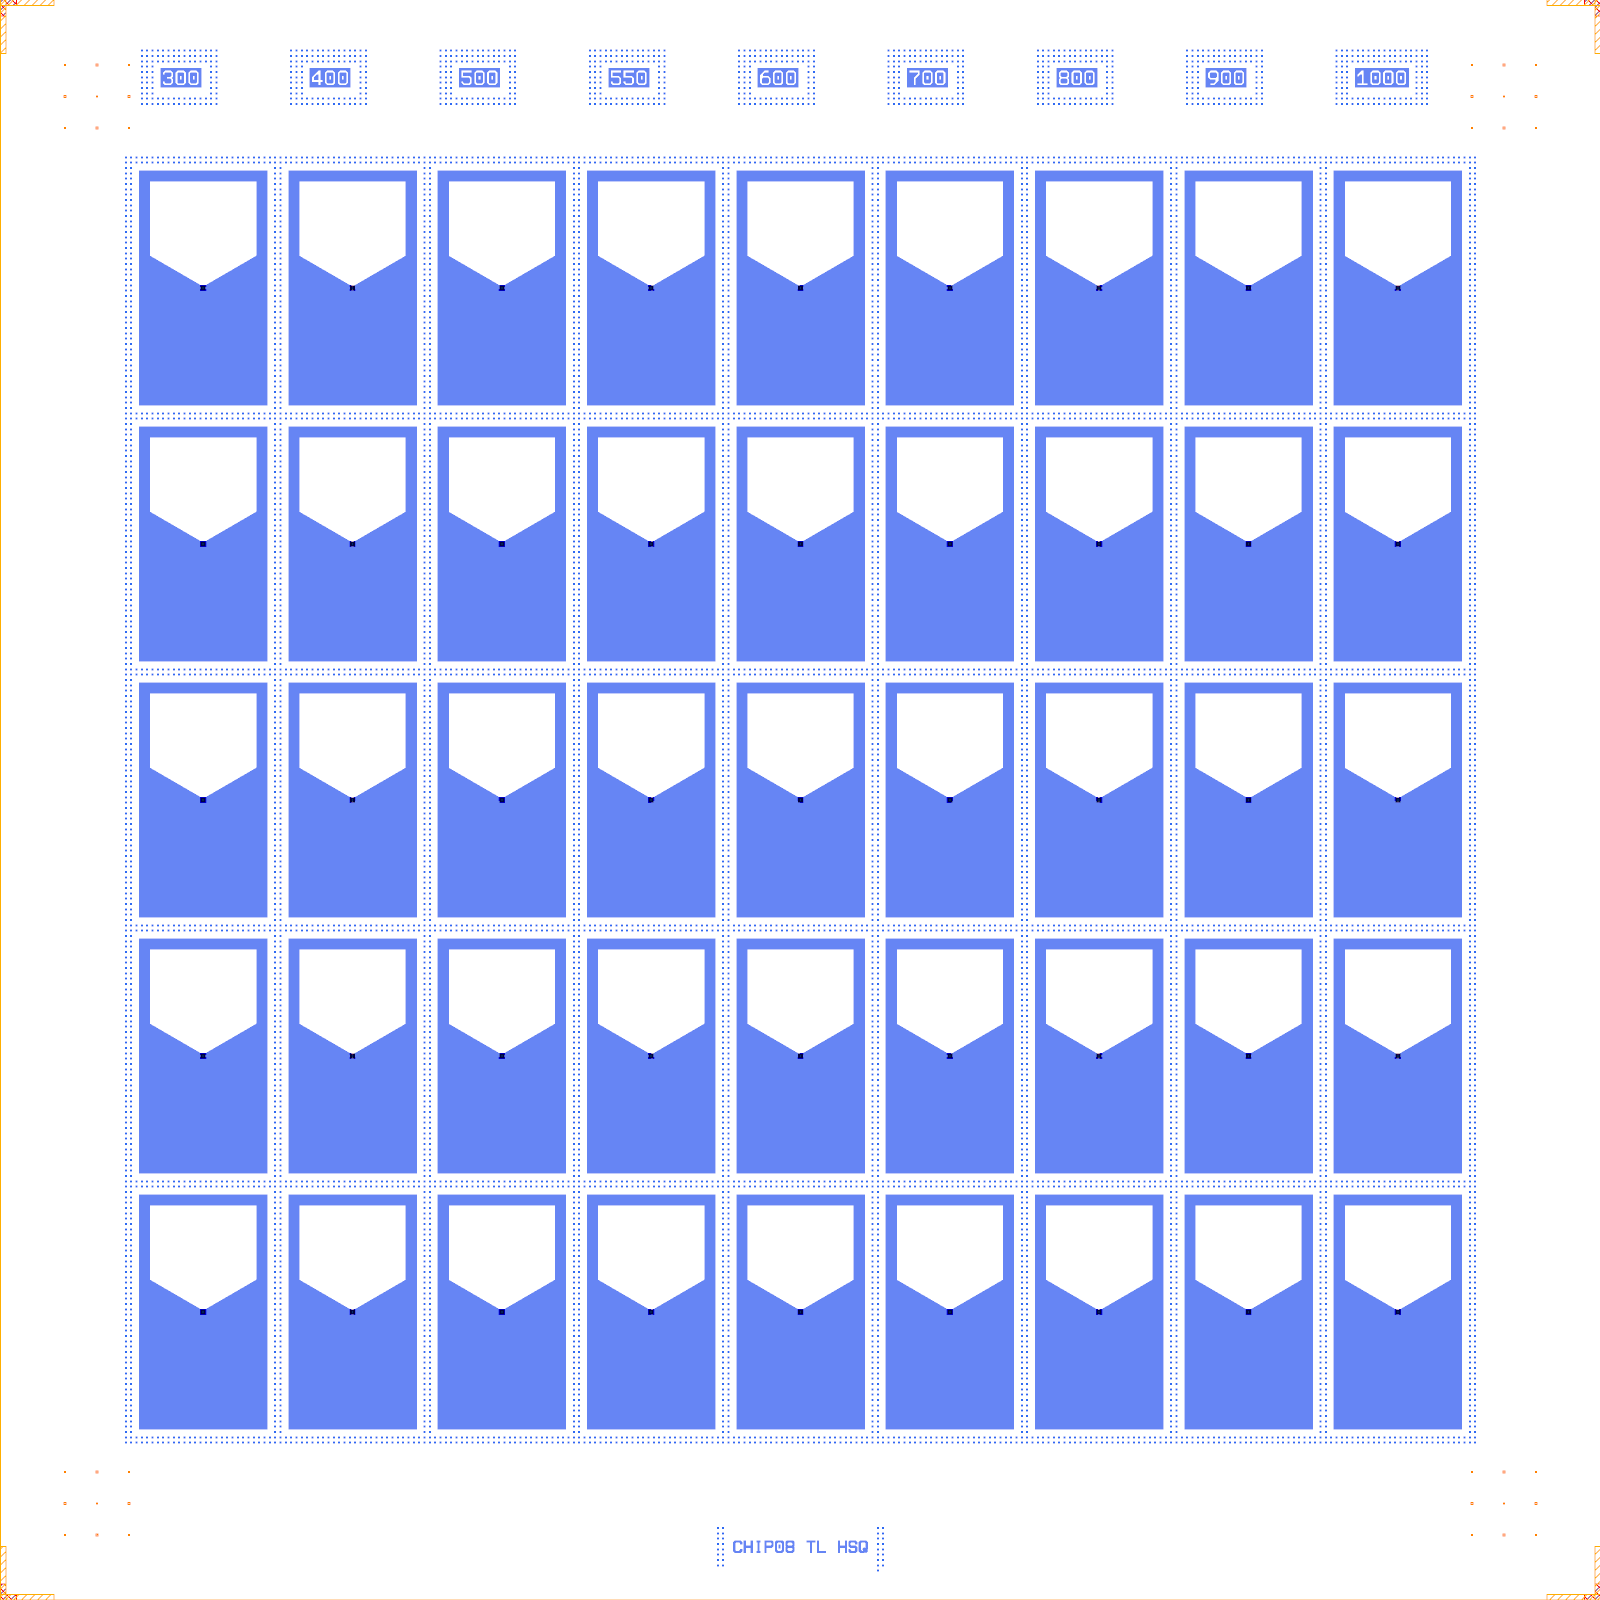

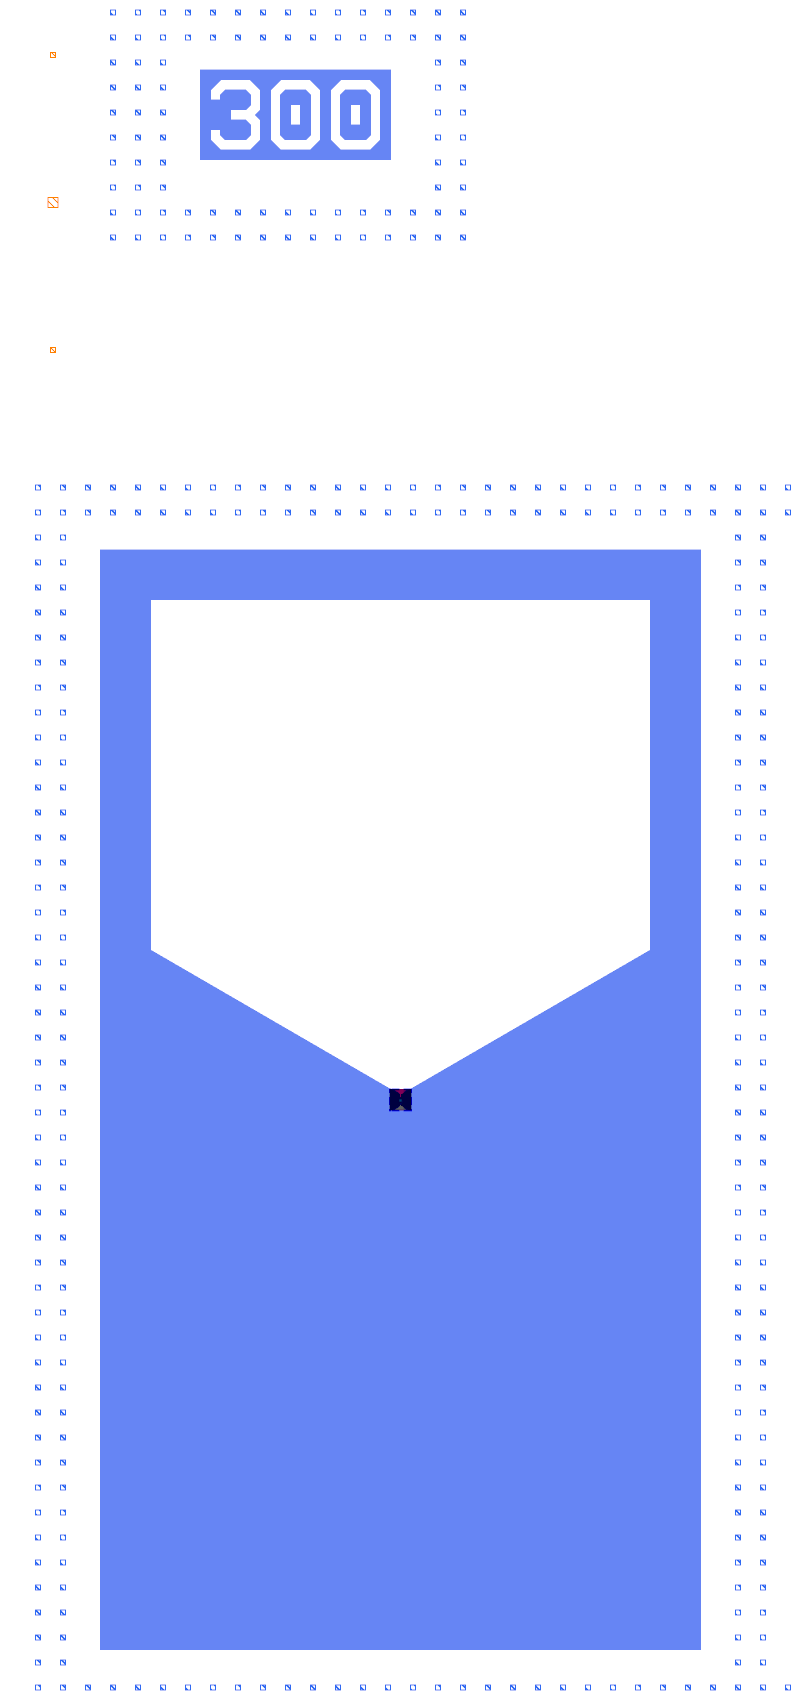

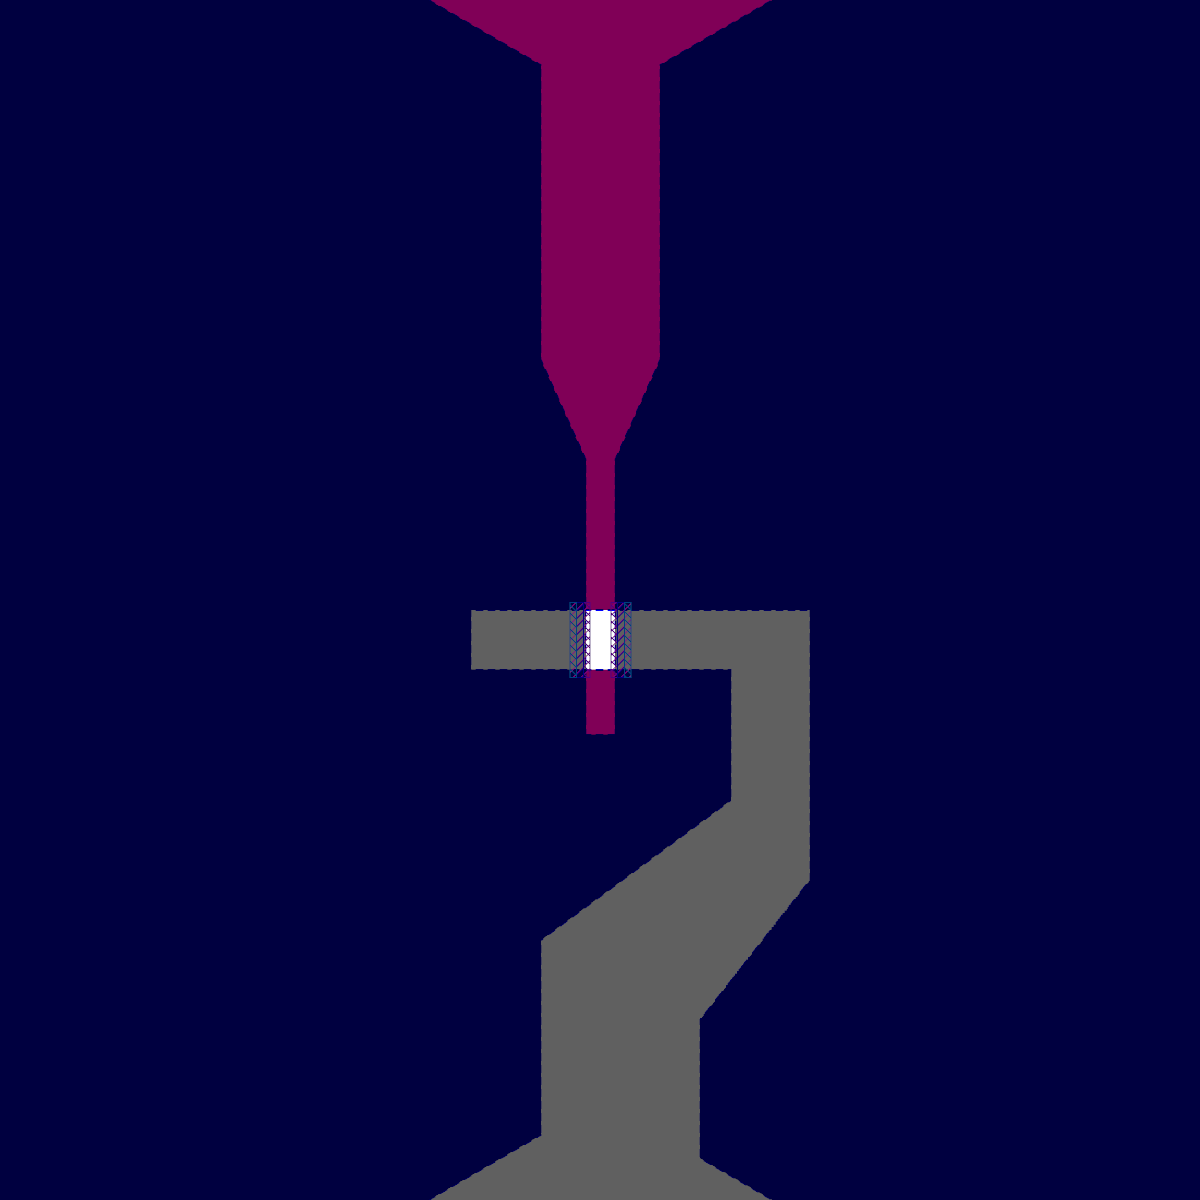

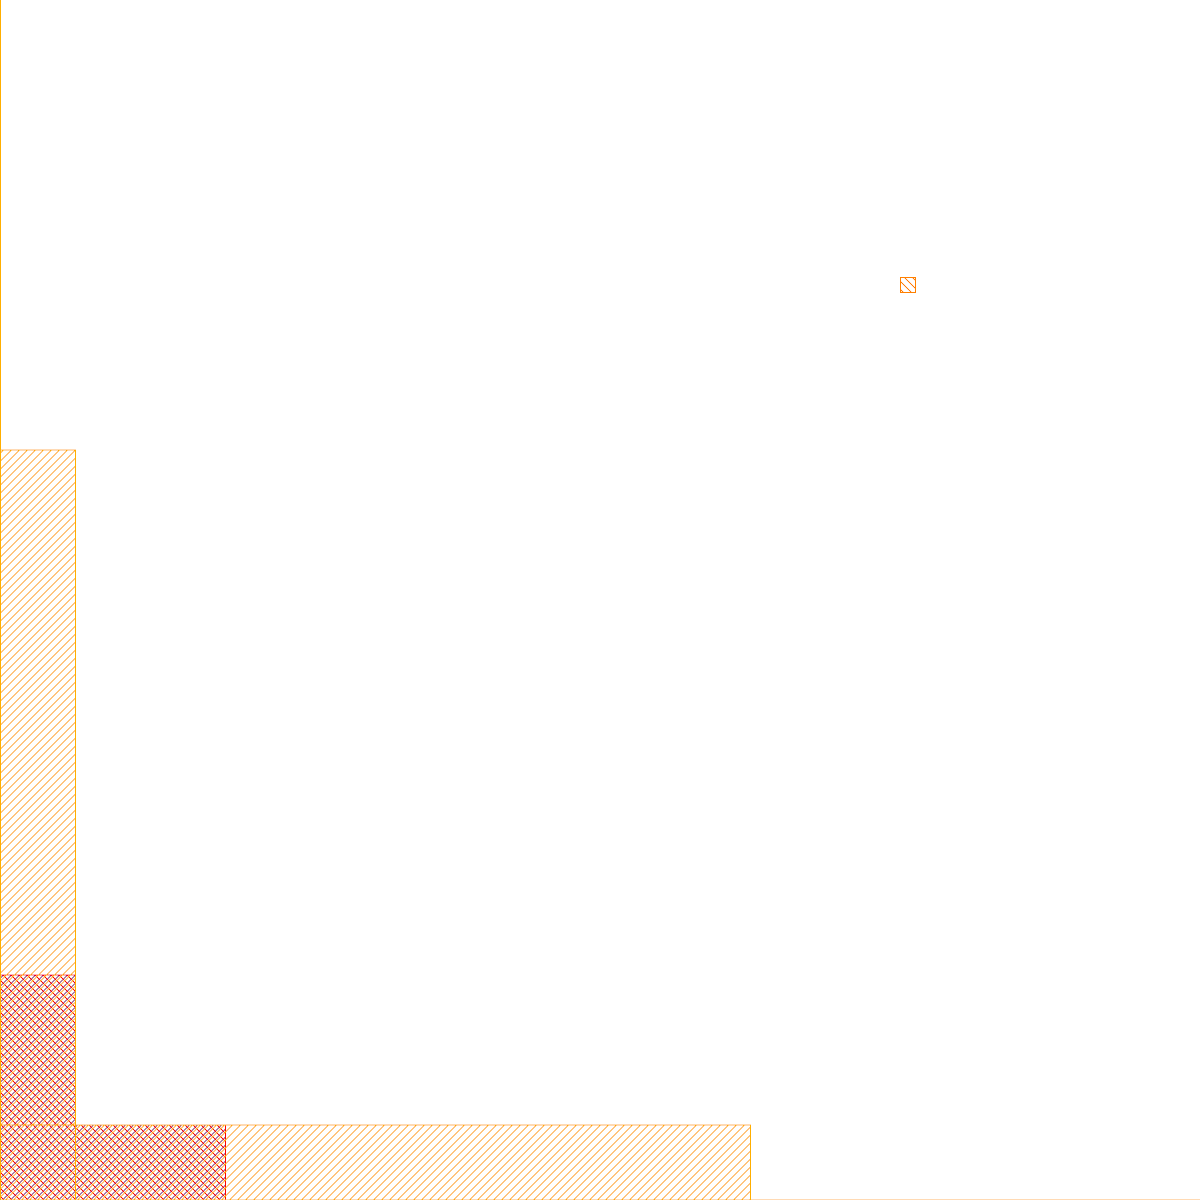

WindowsPath('examples/designs/legacy/chip_08_tl_hsq_testpads_corner.png')

In [15]:
(x0, y0) = L.origin(d, "TP_0_0")
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))   # die box (the instance-name layer reaches past it)
C.show_snapshot(d, OUT / f"{ID}_pad.png", box=(x0 - 400, y0 - 600, x0 + 400, y0 + 1100), size=(800, 1700), width=320)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(x0 - 6, y0 - 6, x0 + 6, y0 + 6), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_corner.png", box=(0, 0, 400, 400), size=(1200, 1200), width=360)

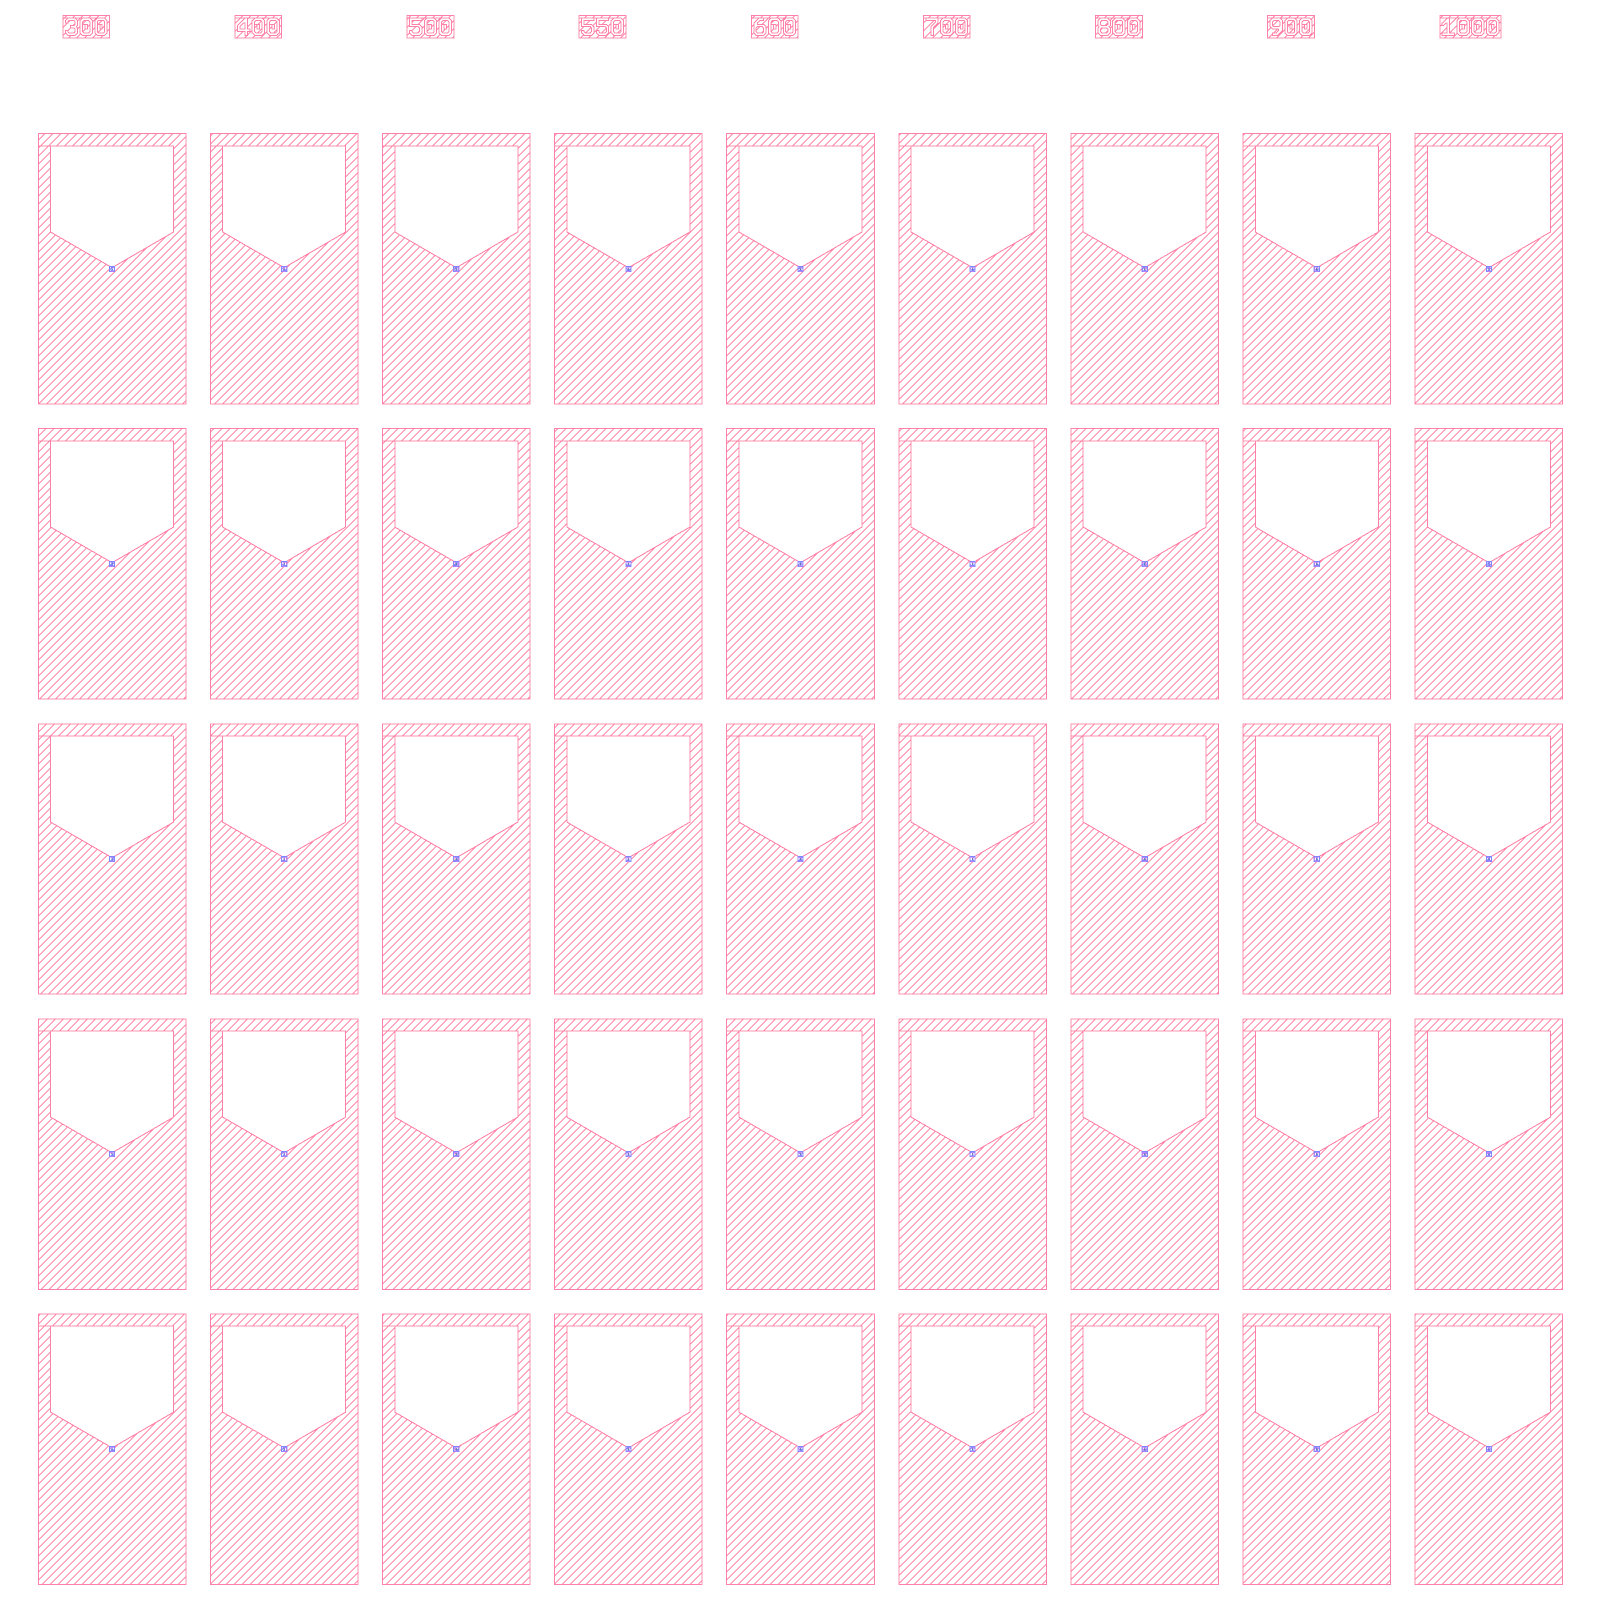

54 legacy instances: largest etch XOR 0.000 µm² (TP_0_0)


| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| TP_0_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_0 | 11250 | 11250 | 0.0 | 0.00% |
| TP_1_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_1 | 11388 | 11388 | 0.0 | 0.00% |
| TP_2_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_2 | 11112 | 11112 | 0.0 | 0.00% |
| TP_3_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_3 | 11275 | 11275 | 0.0 | 0.00% |
| TP_4_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_4 | 11125 | 11125 | 0.0 | 0.00% |
| TP_5_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_5 | 11800 | 11800 | 0.0 | 0.00% |
| TP_6_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_6_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_6_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_6_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_6_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_6 | 10850 | 10850 | 0.0 | 0.00% |
| TP_7_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_7_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_7_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_7_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_7_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_7 | 11125 | 11125 | 0.0 | 0.00% |
| TP_8_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_8_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_8_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_8_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_8_4 | 448393 | 448393 | 0.0 | 0.00% |
| LBL_8 | 14950 | 14950 | 0.0 | 0.00% |

In [16]:
if L.legacy_available():
    ref = LB.legacy_chip(ID)
    for i, bf in enumerate(BOTTOM_FINGER):
        for j, tf in enumerate(TOP_FINGER):
            cell = L.legacy_script_cell(SCRIPT + ".py", "create_testPad", "TEST_TL", bf / 0.2, tf,
                                        tmp=f"build/legacy_b/chip_08/{i}_{j}")
            ref.cell_from(f"TP_{i}_{j}", *cell, X[i], Y[j])
        ref.text(f"LBL_{i}", str(int(bf * 1000)), 100, True, X[i] - 190, LABEL_Y)
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_b/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    print(f"{len(xor)} legacy instances: largest etch XOR {max(xor.values()):.3f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the 45 test pads and the nine column labels at their legacy positions (XOR 0 µm² on all 54
  against the legacy output); the HSQ corner markers.
- **Differs, by the PDK:** the PDK die frame and device ID `CHIP08 TL HSQ` (bottom centre), the PDK cheese band (fab
  cheese source "build", 8647 holes). Centring shift (0, 0).
- **Steps that do not apply:** pads, routes, LOM simulation (junction table instead), FEM.
- **Open:** none (no PDK design warnings). Two columns of the sweep (0.5, 0.55 µm) lie in the PDK window.